# 1. Data exploration

SemEval-2014 Task 4 (laptops and restaurants) after `python -m training.prepare_dataset`.
Every number is computed from `data/processed`.

In [1]:
import sys
from pathlib import Path

# Make `app` and `training` importable from the notebooks folder.
BACKEND = Path.cwd().resolve().parent / "backend" if Path.cwd().name == "notebooks" else Path.cwd() / "backend"
sys.path.insert(0, str(BACKEND))

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)

In [2]:
from training.common import load_split

splits = {name: load_split(name) for name in ("train", "val", "test")}
sentences = pd.DataFrame(
    {"split": name, "domain": r["domain"], "tokens": len(r["tokens"]), "aspects": len(r["aspects"])}
    for name, records in splits.items() for r in records
)
sentences.groupby(["split", "domain"]).agg(
    sentences=("tokens", "size"),
    with_aspects=("aspects", lambda s: int((s > 0).sum())),
    aspect_terms=("aspects", "sum"),
    mean_tokens=("tokens", "mean"),
).round(2)

sentences  with_aspects  aspect_terms  mean_tokens
split domain                                                         
test  laptops            800           422           654        15.24
      restaurants        800           606          1134        16.31
train laptops           2723          1330          2131        17.13
      restaurants       2726          1820          3322        15.98
val   laptops            303           148           210        18.00
      restaurants        303           198           367        15.98

## Polarity of the aspect terms

Positive is the largest class and neutral the smallest, which is why macro-F1 is reported next to accuracy. `conflict` terms are used for aspect extraction but left out of sentiment classification.

polarity,conflict,negative,neutral,positive
domain,,,,
laptops,40,787,417,887
restaurants,86,720,572,1944


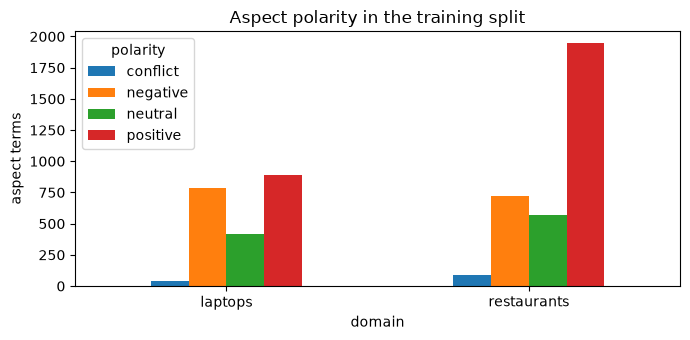

In [3]:
aspects = pd.DataFrame(
    {"split": name, "domain": r["domain"], "term": a["term"].lower(),
     "words": len(a["term"].split()), "polarity": a["polarity"]}
    for name, records in splits.items() for r in records for a in r["aspects"]
)
polarity = aspects[aspects.split == "train"].groupby(["domain", "polarity"]).size().unstack(fill_value=0)
display(polarity)
polarity.plot(kind="bar", figsize=(7, 3.5), rot=0, title="Aspect polarity in the training split")
plt.ylabel("aspect terms"); plt.tight_layout(); plt.show()

## How many aspects does a sentence have?

Many sentences have none: the extraction model must also learn to stay silent.

In [4]:
train = sentences[sentences.split == "train"]
display(train.groupby("domain")["aspects"].value_counts().unstack(fill_value=0).iloc[:, :6])
print("share of training sentences without any aspect:")
print((train.aspects == 0).groupby(train.domain).mean().round(3))

aspects,0,1,2,3,4,5
domain,,,,,,
laptops,1393,823,318,128,40,10
restaurants,906,929,507,240,95,28


share of training sentences without any aspect:
domain
laptops        0.512
restaurants    0.332
Name: aspects, dtype: float64


## Sentences that mix sentiments

Only in these does a model have to be aspect-specific to be right. They are a minority, which is why they are evaluated separately in `docs/results.md`.

In [5]:
def mixed(record):
    polarities = {a["polarity"] for a in record["aspects"] if a["polarity"] != "conflict"}
    return len(polarities) > 1

rows = []
for name, records in splits.items():
    with_aspects = [r for r in records if r["aspects"]]
    rows.append({"split": name, "sentences_with_aspects": len(with_aspects),
                 "mixed": sum(mixed(r) for r in with_aspects)})
table = pd.DataFrame(rows).set_index("split")
table["share_mixed"] = (table.mixed / table.sentences_with_aspects).round(3)
table

,sentences_with_aspects,mixed,share_mixed
split,,,
train,3150,444,0.141
val,346,39,0.113
test,1028,118,0.115


## Most frequent aspect terms and their length

In [6]:
train_aspects = aspects[aspects.split == "train"]
top = {domain: group.term.value_counts().head(15) for domain, group in train_aspects.groupby("domain")}
display(pd.DataFrame({d: [f"{t} ({c})" for t, c in s.items()] for d, s in top.items()}))
print("words per aspect term (share):")
print(train_aspects.groupby("domain").words.value_counts(normalize=True).unstack(fill_value=0).round(3).iloc[:, :4])

,laptops,restaurants
0,screen (58),food (331)
1,price (53),service (209)
2,battery life (51),prices (62)
3,use (49),place (59)
4,keyboard (44),staff (51)
5,battery (42),menu (51)
6,programs (36),dinner (49)
7,software (33),pizza (48)
8,features (33),atmosphere (45)
9,windows (29),price (39)


words per aspect term (share):
words            1      2      3      4
domain                                 
laptops      0.630  0.285  0.061  0.019
restaurants  0.755  0.167  0.048  0.017


## Leakage check

No sentence text may appear in more than one split. `prepare_dataset` removes the overlaps it finds in the official files and fails if any remain; this cell repeats the check.

In [7]:
texts = {name: {r["text"] for r in records} for name, records in splits.items()}
overlap = {f"{a} & {b}": len(texts[a] & texts[b]) for a, b in (("train", "val"), ("train", "test"), ("val", "test"))}
assert not any(overlap.values()), overlap
overlap

{'train & val': 0, 'train & test': 0, 'val & test': 0}